# Chunk 53 — Gupta CNN on the balanced single-band datasets (12×12, 15×15, 35×35, 45×45)

**Why:** Chunk 52 fine-tuned the GATv2 on the Chunk 51 datasets: 5,000 antennas per grid, about 50% single-band and 50% non-functioning, split 4,000 / 500 / 500. This chunk trains the **Gupta CNN on exactly the same splits**, one model per grid as in Chunks 42/44/49, and compares the two models antenna by antenna. **25×25 is not trained.**

**Model:** the Gupta et al. Fig. 4 forward CNN, **flatten readout, no adaptive pooling**, verbatim from Chunks 42/44/49. Parameters: 42,771,473 (12×12), 63,507,473 (15×15), 319,507,473 (35×35) and 524,307,473 (45×45).

**Recipe (Chunks 42/44/49, unchanged):**
- **Optimiser:** NAdam, lr 1e-3, no weight decay, batch 256, gradient clipping 1.0.
- **Schedule:** ReduceLROnPlateau (factor 0.5, patience 5, min lr 1e-6); early stopping with patience 10; at most 300 epochs.
- **Targets:** raw-dB MSE loss; selection on the grid's **new val MSE**.
- **Seeds:** torch 1000+s, data order 2000+s. Seeds 0 and 1 by default; **seed 0 is the headline**, as for the GATv2.

**Data:** the Chunk 51 split files `splits/ch51_{N}x{N}_{train,val,test}.json`, where `35x35_extra` is Chunk 45's zip. The CNN image is the metal column of the graph's pixel nodes, reshaped to 1×N×N, exactly as in Chunks 36–49.

**GPU memory:** the 45×45 CNN needs roughly 25–30 GB at batch 256. A memory probe picks the largest micro-batch that fits and accumulates gradients so each step still sees 256 antennas; the run records `micro_batch`.

**Test (one touch):** every CNN on its grid's new test set (500 antennas). The GATv2 side comes from Chunk 52's saved per-antenna results (`ch52_per_sample.parquet`, final model `bal_ft45_s0`), so **every comparison is paired** on the same test antennas.

**Pre-registered statements:**

| | question |
|---|---|
| S1 | On each grid, is the GATv2 (Chunk 52 final) better than the Gupta CNN (seed 0) in test MSE and MAE? |
| S2 | Does the answer hold separately for single-band and non-functioning antennas? |
| S3 | Do the two CNN seeds agree? |

**Results apply to single-band and non-functioning antennas only, and are not comparable with the natural-distribution table.**

**Writes:**
- `ch53_*` artifacts: runs, curves, per-sample with predicted curves, metrics, paired comparisons, report
- `ch53_table_gatv2_vs_gupta_cnn.{png,pdf}`
- `checkpoints/ch53_cnn{N}_bal_s{seed}.pt`

## 1. Installs

In [1]:
!pip -q install torch_geometric pyarrow tabulate

## 2. Repository and Drive

In [11]:
import os, sys, subprocess
REPO_ROOT = '/content/antenna_gnn'
if os.path.isdir(f'{REPO_ROOT}/.git'):
    subprocess.run(['git', '-C', REPO_ROOT, 'pull', '-q'], check=True)
else:
    subprocess.run(['git', 'clone', '-q', 'https://github.com/asparagusD/antenna_gnn.git', REPO_ROOT], check=True)
sys.path.insert(0, f'{REPO_ROOT}/src')
from google.colab import drive
drive.mount('/content/drive')
DATA_ROOT = '/content/drive/MyDrive/antenna_gnn'
ART, CKPT, SPLITS, LOCAL = f'{DATA_ROOT}/artifacts', f'{DATA_ROOT}/checkpoints', f'{DATA_ROOT}/splits', '/content/local_graphs'
os.makedirs(LOCAL, exist_ok=True)
print(REPO_ROOT, DATA_ROOT)

Mounted at /content/drive
/content/antenna_gnn /content/drive/MyDrive/antenna_gnn


## 3. Setup
- **Determinism:** deterministic cuDNN, TF32 off.
- **Provenance:** hashes every input file and captures the mtimes of earlier files, so the guards can prove nothing earlier was changed.
- **GPU check:** reports whether the GPU has enough memory for a true batch of 256 at 45×45.

In [3]:
# ── Setup: scope, provenance, determinism ──
import json, glob, hashlib, zipfile, shutil, time, textwrap
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader as TorchLoader
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

TAU, F = -10.0, np.linspace(1, 4, 201)
GRIDS = (12, 15, 35, 45)                       # 25x25 is not trained
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); assert DEVICE.type == 'cuda', 'GPU required'
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 1e9
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False
def sha(p):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for b in iter(lambda: f.read(1 << 20), b''):
            h.update(b)
    return h.hexdigest()
READ_SHA = {}
def READ(p):
    assert os.path.exists(p), f'missing {p}'
    READ_SHA.setdefault(p, sha(p)); return p
def OUT(n):
    assert n.startswith('ch53_'), n; return f'{ART}/{n}'
def COUT(n):
    assert n.startswith('ch53_') and n.endswith('.pt'), n; return f'{CKPT}/{n}'
PRIOR = {p: os.path.getmtime(p) for pat in (f'{ART}/*', f'{SPLITS}/*', f'{CKPT}/*.pt') for p in glob.glob(pat)
         if os.path.isfile(p) and not Path(p).name.startswith('ch53_')}
TEST_TOUCHES = 0
print(f'GPU: {torch.cuda.get_device_name(0)} ({GPU_GB:.0f} GB) | captured mtimes of {len(PRIOR)} earlier files')
if GPU_GB < 38:
    print('NOTE: under 40 GB; the 45x45 CNN will use gradient accumulation (effective batch still 256), recorded per run.')

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition (102 GB) | captured mtimes of 313 earlier files


## 4. Splits
The Chunk 51 split files, checked to be exactly 4,000 / 500 / 500 with no overlap. Class labels come from `ch51_manifest.parquet`.

In [4]:
# ── Splits: Chunk 51 ──
S = {}
for N in GRIDS:
    S[N] = {r: [(str(a), int(b)) for a, b in json.load(open(READ(f'{SPLITS}/ch51_{N}x{N}_{r}.json')))] for r in ('train', 'val', 'test')}
    a, b, c = (set(S[N][r]) for r in ('train', 'val', 'test'))
    assert (len(a), len(b), len(c)) == (4000, 500, 500) and not (a & b or a & c or b & c), f'STOP: {N}x{N} Chunk 51 splits'
MAN51 = pd.read_parquet(READ(f'{ART}/ch51_manifest.parquet'))
CLS = {(r.source, int(r.sample_idx)): r.cls for r in MAN51[MAN51.selected].itertuples()}
for N in GRIDS:
    assert all(k in CLS for r in ('train', 'val', 'test') for k in S[N][r]), f'STOP: {N}x{N} split not in the Chunk 51 manifest'
    print(f'{N}x{N}: train 4,000 | val 500 | test 500 | test single-band {sum(CLS[k] == "single_band" for k in S[N]["test"])}')

12x12: train 4,000 | val 500 | test 500 | test single-band 250
15x15: train 4,000 | val 500 | test 500 | test single-band 250
35x35: train 4,000 | val 500 | test 500 | test single-band 254
45x45: train 4,000 | val 500 | test 500 | test single-band 260


## 5. Stage graphs; CNN images
**What it does:**
- Unzips each grid's processed graphs, plus `processed_35x35_extra.zip`.
- Builds the 1×N×N metal image and the raw-dB target for every antenna in the new splits.
- Builds the old Chunk 42 12×12 val images too, for the harness only.

In [5]:
# ── Stage graphs; build images ──
SRC = [f'{N}x{N}' for N in GRIDS] + ['35x35_extra']
FOLDER = {s: f'{LOCAL}/{s}' for s in SRC}
for s in SRC:
    d = FOLDER[s]
    if os.path.exists(f'{d}/_STAGED.txt'):
        continue
    os.makedirs(d, exist_ok=True)
    with zipfile.ZipFile(READ(f'{DATA_ROOT}/data/processed/processed_{s}.zip')) as Z:
        mem = [m for m in Z.namelist() if m.endswith('.pt')]
        for m in tqdm(mem, desc=f'stage {s}'):
            with Z.open(m) as a, open(f'{d}/{os.path.basename(m)}', 'wb') as b:
                shutil.copyfileobj(a, b)
    open(f'{d}/_STAGED.txt', 'w').write(str(len(mem)))
def raw(key):
    src, i = key; n_ = int(src.split('x')[0])
    d = torch.load(f'{FOLDER[src]}/sample_{int(i)}.pt', weights_only=False)
    assert d.x.shape == (n_ * n_ + 1, 5) and float(d.x[-1, 3]) == -1.0 and d.y.numel() == 201 and float(d.y.max()) <= 0.01
    return d
def build(keys, N):
    ds = [raw(k) for k in tqdm(keys, desc=f'images {N}x{N}', leave=False)]
    return (torch.stack([d.x[:-1, 0].reshape(1, N, N) for d in ds]).float(), torch.stack([d.y.reshape(-1) for d in ds]).float())
IMG, CUR = {}, {}
for N in GRIDS:
    for r in ('train', 'val', 'test'):
        IMG[(N, r)], CUR[(N, r)] = build(S[N][r], N)
OLD12_VAL = sorted(int(e[1]) for e in json.load(open(READ(f'{SPLITS}/finetune12_val_indices.json'))))
IMG[(12, 'oldval')], CUR[(12, 'oldval')] = build([('12x12', i) for i in OLD12_VAL], 12)
print({k: tuple(v.shape) for k, v in IMG.items()})

stage 12x12:   0%|          | 0/7000 [00:00<?, ?it/s]

stage 15x15:   0%|          | 0/6367 [00:00<?, ?it/s]

stage 35x35:   0%|          | 0/4988 [00:00<?, ?it/s]

stage 45x45:   0%|          | 0/6984 [00:00<?, ?it/s]

stage 35x35_extra:   0%|          | 0/1997 [00:00<?, ?it/s]

images 12x12:   0%|          | 0/4000 [00:00<?, ?it/s]

... (9 outputs left out)

images 45x45:   0%|          | 0/500 [00:00<?, ?it/s]

images 45x45:   0%|          | 0/500 [00:00<?, ?it/s]

images 12x12:   0%|          | 0/700 [00:00<?, ?it/s]

{(12, 'train'): (4000, 1, 12, 12), (12, 'val'): (500, 1, 12, 12), (12, 'test'): (500, 1, 12, 12), (15, 'train'): (4000, 1, 15, 15), (15, 'val'): (500, 1, 15, 15), (15, 'test'): (500, 1, 15, 15), (35, 'train'): (4000, 1, 35, 35), (35, 'val'): (500, 1, 35, 35), (35, 'test'): (500, 1, 35, 35), (45, 'train'): (4000, 1, 45, 45), (45, 'val'): (500, 1, 45, 45), (45, 'test'): (500, 1, 45, 45), (12, 'oldval'): (700, 1, 12, 12)}


## 6. Model
`GuptaCNN(N)`, verbatim from Chunks 42/44/49. Each parameter count must equal 6,163,473 − 257,000 + (256·N²·1000 + 1000), the formula that reproduces every earlier CNN.

In [6]:
# ── Gupta CNN (verbatim from Chunks 42/44/49) ──
class GuptaCNN(nn.Module):
    # Gupta et al. Fig. 4 forward CNN (Chunk 36 architecture, flatten readout) for an N x N input
    def __init__(self, N):
        super().__init__()
        self.block1 = nn.Sequential(nn.Conv2d(1,64,5,padding=2), nn.BatchNorm2d(64), nn.LeakyReLU(.2), nn.Conv2d(64,64,5,padding=2),
                                    nn.BatchNorm2d(64), nn.LeakyReLU(.2), nn.Conv2d(64,64,5,padding=2), nn.BatchNorm2d(64), nn.LeakyReLU(.2))
        b2 = [nn.Conv2d(64,128,3,padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(.2)]
        for _ in range(4): b2 += [nn.Conv2d(128,128,3,padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(.2)]
        self.block2 = nn.Sequential(*b2)
        b3 = [nn.Conv2d(128,256,3,padding=1), nn.BatchNorm2d(256), nn.LeakyReLU(.2)]
        for _ in range(7): b3 += [nn.Conv2d(256,256,3,padding=1), nn.BatchNorm2d(256), nn.LeakyReLU(.2)]
        self.block3 = nn.Sequential(*b3)
        self.fc = nn.Sequential(nn.Linear(256*N*N,1000), nn.BatchNorm1d(1000), nn.LeakyReLU(.2), nn.Dropout(.4),
                                nn.Linear(1000,500), nn.BatchNorm1d(500), nn.LeakyReLU(.2), nn.Dropout(.4), nn.Linear(500,201))
    def forward(self, x):
        return self.fc(self.block3(self.block2(self.block1(x))).flatten(1))
def n_par(m): return sum(p.numel() for p in m.parameters())
def expected_cnn_params(N): return 6_163_473 - 257_000 + 256_000 * N * N + 1000
def cnn(N):
    m = GuptaCNN(N); assert n_par(m) == expected_cnn_params(N), (N, n_par(m)); return m
def state_of(path):
    c = torch.load(READ(path), map_location='cpu', weights_only=False)
    s = c['model_state'] if isinstance(c, dict) and 'model_state' in c else c
    return {k[7:] if k.startswith('module.') else k: v for k, v in s.items()}
@torch.no_grad()
def predict(m, X, bs=128):
    m = m.to(DEVICE).eval()
    return torch.cat([m(X[s:s + bs].to(DEVICE)).double().cpu() for s in range(0, len(X), bs)]).numpy()
for N in GRIDS:
    print(f'Gupta CNN {N}x{N}: {expected_cnn_params(N):,} parameters')

Gupta CNN 12x12: 42,771,473 parameters
Gupta CNN 15x15: 63,507,473 parameters
Gupta CNN 35x35: 319,507,473 parameters
Gupta CNN 45x45: 524,307,473 parameters


## 7. VAL harness (before training)
**Image pipeline check:** the Chunk 42 `cnn12_p100_s0` checkpoint must reproduce its recorded val MSE on its own old 12×12 val split (`ch42_runs.csv`). This proves the image pipeline and the class are unchanged.

**Baseline:** prints the average-curve baseline on every new val set, the error of always predicting the mean training curve.

In [7]:
# ── VAL harness ──
R42 = pd.read_csv(READ(f'{ART}/ch42_runs.csv')).set_index('run_id')
m = cnn(12); m.load_state_dict(state_of(f'{CKPT}/ch42_cnn12_p100_s0.pt'), strict=True)
v = float(((predict(m, IMG[(12, 'oldval')]) - CUR[(12, 'oldval')].numpy().astype(np.float64)) ** 2).mean())
ref = float(R42.loc['cnn12_p100_s0', 'val12_mse_db2'])
print(f'cnn12_p100_s0 old 12x12 VAL MSE {v:.4f} | Chunk 42 {ref:.4f}')
assert abs(v - ref) < 2e-3, 'STOP: image pipeline or CNN class does not reproduce Chunk 42'
del m; torch.cuda.empty_cache()
for N in GRIDS:
    T = CUR[(N, 'val')].numpy().astype(np.float64); base = CUR[(N, 'train')].numpy().mean(0, keepdims=True)
    print(f'{N}x{N} average-curve baseline VAL MSE {((base - T) ** 2).mean():.4f}')
HARNESS = True

cnn12_p100_s0 old 12x12 VAL MSE 2.5916 | Chunk 42 2.5916
12x12 average-curve baseline VAL MSE 3.5454
15x15 average-curve baseline VAL MSE 4.6429
35x35 average-curve baseline VAL MSE 3.5972
45x45 average-curve baseline VAL MSE 3.4493


## 8. Train (resumable queue)
**Queue:** seed 0 for 12, 15, 35, 45, then seed 1 for the same grids. Set `SEEDS = (0,)` to train only the headline seed.
- A finished run is skipped, and a session budget stops the queue cleanly.

**Memory:** before each run, a probe finds the largest micro-batch (256, 128, 64 or 32) that fits for one forward and backward pass. Gradients are accumulated so each step still sees 256 antennas.

**Checkpoints:** the best model by val MSE is mirrored to Drive with a forced flush and verified by SHA-256.

**Writes:** `ch53_curves.csv`, `ch53_runs.csv`, `checkpoints/ch53_cnn{N}_bal_s{seed}.pt`.

In [12]:
# ── Training: one Gupta CNN per grid ──
RECIPE = dict(lr=1e-3, wd=0.0, batch=256, patience=10, max_ep=300)       # Chunk 42/44/49, unchanged
SEEDS = (0, 1)
QUEUE = [(N, s) for s in SEEDS for N in GRIDS]
CURVES, RUNS = OUT('ch53_curves.csv'), OUT('ch53_runs.csv')
SESSION_HOURS = 10; T0S = time.perf_counter(); TIMES = []
def rid(N, s): return f'cnn{N}_bal_s{s}'
def done(): return set(pd.read_csv(RUNS).run_id) if os.path.exists(RUNS) else set()
def append(df, p):
    if os.path.exists(p):
        df = pd.concat([pd.read_csv(p), df], ignore_index=True)    # align by column name
    df.to_csv(p, index=False)
def mirror(local, drive_path):
    shutil.copy2(local, drive_path); h = sha(local)
    drive.flush_and_unmount(); drive.mount('/content/drive', force_remount=True)
    assert sha(drive_path) == h, f'STOP: {Path(drive_path).name} did not persist'
    return h
def probe_micro(N):
    for mb in (256, 128, 64, 32):
        m = opt = None
        try:
            torch.cuda.empty_cache(); m = cnn(N).to(DEVICE).train(); opt = torch.optim.NAdam(m.parameters(), lr=1e-3)
            x = torch.rand(mb, 1, N, N, device=DEVICE).round(); y = torch.randn(mb, 201, device=DEVICE)
            nn.functional.mse_loss(m(x), y).backward(); opt.step(); torch.cuda.synchronize()
            return mb
        except torch.cuda.OutOfMemoryError:
            pass
        finally:
            del m, opt; torch.cuda.empty_cache()
    raise RuntimeError(f'STOP: the {N}x{N} CNN does not fit even at micro-batch 32')
def val_metrics(m, N):
    P = predict(m, IMG[(N, 'val')]); T = CUR[(N, 'val')].numpy().astype(np.float64)
    return float(((P - T) ** 2).mean()), float(np.abs(P - T).mean()), float(roc_auc_score(T.min(1) < TAU, -P.min(1)))

def train(N, s):
    r = rid(N, s); out = COUT(f'ch53_{r}.pt')
    if r in done() and os.path.exists(out):
        print('skip', r); return
    mb = probe_micro(N); acc = RECIPE['batch'] // mb
    print(f'{r}: micro-batch {mb} x {acc} = effective batch {mb * acc}')
    torch.manual_seed(1000 + s); torch.cuda.manual_seed_all(1000 + s)
    m = cnn(N).to(DEVICE); opt = torch.optim.NAdam(m.parameters(), lr=RECIPE['lr'], weight_decay=RECIPE['wd'])
    g = torch.Generator().manual_seed(2000 + s)
    loader = TorchLoader(TensorDataset(IMG[(N, 'train')], CUR[(N, 'train')]), batch_size=RECIPE['batch'], shuffle=True, generator=g)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=5, min_lr=1e-6)
    best, bad, best_row, steps, t0 = float('inf'), 0, None, 0, time.perf_counter()
    best_local = f'/content/{r}.best'
    if os.path.exists(CURVES):
        C = pd.read_csv(CURVES); C[C.run_id != r].to_csv(CURVES, index=False)

    # Wrap epochs in a tqdm progress bar with live metrics tracking
    epoch_bar = tqdm(range(1, RECIPE['max_ep'] + 1), desc=f'Training {r}', leave=True)
    for ep in epoch_bar:
        m.train(); tot_mse, tot_mae, n = 0.0, 0.0, 0
        for x, y in loader:
            opt.zero_grad(set_to_none=True); B = len(x)
            for xs, ys in zip(x.split(mb), y.split(mb)):
                xs, ys = xs.to(DEVICE), ys.to(DEVICE); pred = m(xs)
                loss = nn.functional.mse_loss(pred, ys); (loss * len(xs) / B).backward()
                tot_mse += loss.item() * len(xs); tot_mae += nn.functional.l1_loss(pred, ys).item() * len(xs); n += len(xs)
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); steps += 1
        vmse, vmae, vauc = val_metrics(m, N); sch.step(vmse)

        # Update tqdm progress bar description/postfix
        epoch_bar.set_postfix({
            'val_MSE': f'{vmse:.4f}',
            'val_MAE': f'{vmae:.4f}',
            'best_MSE': f'{min(best, vmse):.4f}',
            'lr': f'{opt.param_groups[0]["lr"]:.1e}'
        })

        print(f'{r} epoch {ep:3d} | train MSE {tot_mse / n:.4f} | val MSE {vmse:.4f} | val MAE {vmae:.4f} | best {min(best, vmse):.4f}')
        row = dict(run_id=r, grid=N, seed=s, epoch=ep, steps=steps, wall_seconds=time.perf_counter() - t0, train_mse_db2=tot_mse / n,
                   val_mse_db2=vmse, val_mae_db=vmae, val_auroc=vauc, lr=opt.param_groups[0]['lr'])
        append(pd.DataFrame([row]), CURVES)
        if vmse < best:
            best, bad, best_row = vmse, 0, row
            torch.save({'model_state': m.state_dict(), 'grid': N, 'seed': s, 'best_epoch': ep, 'best_val_mse': vmse, 'micro_batch': mb}, best_local)
        else:
            bad += 1
        if bad >= RECIPE['patience']:
            break
    h = mirror(best_local, out)
    rec = dict(run_id=r, grid=N, seed=s, n_train=len(IMG[(N, 'train')]), n_params=n_par(m), micro_batch=mb, effective_batch=mb * acc,
               best_epoch=best_row['epoch'], epochs_run=ep, minutes=(time.perf_counter() - t0) / 60, val_mse_db2=best_row['val_mse_db2'],
               val_mae_db=best_row['val_mae_db'], val_auroc=best_row['val_auroc'],
               budget_limited=bool(best_row['epoch'] > RECIPE['max_ep'] - RECIPE['patience']), checkpoint=out, checkpoint_sha256=h)
    append(pd.DataFrame([rec]), RUNS); TIMES.append(rec['minutes'] * 60); os.remove(best_local)
    del m, opt; torch.cuda.empty_cache()
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in rec.items() if k not in ('checkpoint', 'checkpoint_sha256')})

assert globals().get('HARNESS') is True
for job in QUEUE:
    used = (time.perf_counter() - T0S) / 3600
    if TIMES and used + max(TIMES) / 3600 > SESSION_HOURS:
        print(f'session budget reached ({used:.1f} h): re-run this cell in a new session to continue'); break
    train(*job)
print('completed:', len(done()), 'of', len(QUEUE))

skip cnn12_bal_s0
skip cnn15_bal_s0
skip cnn35_bal_s0
skip cnn45_bal_s0
skip cnn12_bal_s1
skip cnn15_bal_s1
skip cnn35_bal_s1
cnn45_bal_s1: micro-batch 256 x 1 = effective batch 256


Training cnn45_bal_s1:   0%|          | 0/300 [00:00<?, ?it/s]

cnn45_bal_s1 epoch   1 | train MSE 4.4894 | val MSE 861.3252 | val MAE 16.6325 | best 861.3252
cnn45_bal_s1 epoch   2 | train MSE 2.2192 | val MSE 75.4789 | val MAE 3.7276 | best 75.4789
cnn45_bal_s1 epoch   3 | train MSE 1.8916 | val MSE 8.4350 | val MAE 1.1207 | best 8.4350
cnn45_bal_s1 epoch   4 | train MSE 1.8448 | val MSE 2.3192 | val MAE 0.6122 | best 2.3192
cnn45_bal_s1 epoch   5 | train MSE 1.7565 | val MSE 1.6474 | val MAE 0.5150 | best 1.6474
cnn45_bal_s1 epoch   6 | train MSE 1.7380 | val MSE 1.9084 | val MAE 0.5241 | best 1.6474
cnn45_bal_s1 epoch   7 | train MSE 1.6942 | val MSE 2.3108 | val MAE 0.6009 | best 1.6474
cnn45_bal_s1 epoch   8 | train MSE 1.6334 | val MSE 1.5207 | val MAE 0.4348 | best 1.5207
cnn45_bal_s1 epoch   9 | train MSE 1.6542 | val MSE 3.0664 | val MAE 0.6789 | best 1.5207
cnn45_bal_s1 epoch  10 | train MSE 1.6409 | val MSE 1.5462 | val MAE 0.4823 | best 1.5207
cnn45_bal_s1 epoch  11 | train MSE 1.5941 | val MSE 2.1940 | val MAE 0.5620 | best 1.5207
cnn

## 9. TEST TOUCH
The only cell that scores test images, guarded by a counter.

**What it does:**
- Scores every Chunk 53 CNN on its grid's new test set.
- Reads the GATv2 final model's (`bal_ft45_s0`, and `bal_ft45_s1` if present) per-antenna results from `ch52_per_sample.parquet`.
- Checks that the Chunk 52 file covers exactly the same 500 test antennas per grid, and that its stored mean MSE matches `ch52_metrics.csv`.

**Writes:** `ch53_per_sample.parquet`, with errors, class and the full predicted curve for every CNN test antenna.

In [13]:
# ── TEST TOUCH (the only cell that scores test images) ──
assert globals().get('HARNESS') is True and TEST_TOUCHES == 0; TEST_TOUCHES += 1
RUNS_DF = pd.read_csv(RUNS)
assert {rid(N, 0) for N in GRIDS} <= set(RUNS_DF.run_id), 'STOP: train the seed-0 CNNs first'
rows = []

# Wrap the run loop with tqdm to track prediction progress
for rr in tqdm(list(RUNS_DF.itertuples()), desc="Scoring test sets"):
    N = int(rr.grid); m = cnn(N); m.load_state_dict(state_of(rr.checkpoint), strict=True)
    P = predict(m, IMG[(N, 'test')]); T = CUR[(N, 'test')].numpy().astype(np.float64); del m; torch.cuda.empty_cache()
    for k, key in enumerate(S[N]['test']):
        rows.append(dict(family='Gupta CNN', model_id=rr.run_id, grid=N, source=key[0], sample_idx=key[1], cls=CLS[key],
                         true_min_db=T[k].min(), pred_min_db=P[k].min(), mse_db2=((P[k] - T[k]) ** 2).mean(),
                         mae_db=np.abs(P[k] - T[k]).mean(), y_hat=P[k].astype(np.float32).tolist()))
CNNPER = pd.DataFrame(rows); CNNPER.to_parquet(OUT('ch53_per_sample.parquet'), index=False)
print(f'TEST touched once: {len(RUNS_DF)} CNNs; {len(CNNPER):,} rows')
# GATv2 side: Chunk 52 saved per-antenna results (no checkpoint needed)
P52 = pd.read_parquet(READ(f'{ART}/ch52_per_sample.parquet'), columns=['model_id', 'grid', 'source', 'sample_idx', 'cls', 'true_min_db',
                                                                     'pred_min_db', 'mse_db2', 'mae_db'])
M52 = pd.read_csv(READ(f'{ART}/ch52_metrics.csv'))
GNN_IDS = [g for g in ('bal_ft45_s0', 'bal_ft45_s1') if g in set(P52.model_id)]
assert 'bal_ft45_s0' in GNN_IDS, 'STOP: Chunk 52 final model missing from ch52_per_sample.parquet'
GPER = P52[P52.model_id.isin(GNN_IDS) & P52.grid.isin(GRIDS)].assign(family='GATv2')
for N in GRIDS:
    g = GPER[(GPER.model_id == 'bal_ft45_s0') & (GPER.grid == N)]
    assert sorted(zip(g.source, g.sample_idx)) == sorted(S[N]['test']), f'STOP: Chunk 52 {N}x{N} test antennas differ'
    ref = float(M52[(M52.model_id == 'bal_ft45_s0') & (M52.grid == N) & (M52.subset == 'all') & (M52.metric == 'mse_db2')].estimate.iloc[0])
    assert abs(g.mse_db2.mean() - ref) < 1e-6, f'STOP: Chunk 52 {N}x{N} per-sample MSE does not match its metrics'
PER = pd.concat([CNNPER.drop(columns='y_hat'), GPER], ignore_index=True)
print('GATv2 models read from Chunk 52:', GNN_IDS)

Scoring test sets:   0%|          | 0/8 [00:00<?, ?it/s]

TEST touched once: 8 CNNs; 4,000 rows
GATv2 models read from Chunk 52: ['bal_ft45_s0', 'bal_ft45_s1']


## 10. Metrics, paired comparisons, statements
**Metrics per model and grid:** MSE, RMSE, MAE, R² and AUROC, plus MSE and MAE per class, with 95% stratified bootstrap intervals (1,000 resamples, rng 531).

**Paired comparisons** (same test antennas, rng 532):
- GATv2 (`bal_ft45_s0`) − CNN (seed 0), per grid: all antennas (S1), then single-band and non-functioning separately (S2)
- CNN seed 1 − seed 0 (S3)

**Writes:** `ch53_metrics.csv`, `ch53_paired.csv`.

In [14]:
# ── Metrics, paired comparisons, statements ──
R = 1000
def boot_ci(x, rng):
    bs = [x[rng.integers(0, len(x), len(x))].mean() for _ in range(R)]; return np.quantile(bs, .025), np.quantile(bs, .975)
rows = []
for (mid, N), d in PER.groupby(['model_id', 'grid']):
    fam = d.family.iloc[0]; y = (d.true_min_db.values < TAU).astype(int)
    for subset, dd in [('all', d), ('single_band', d[d.cls == 'single_band']), ('non_functioning', d[d.cls == 'non_functioning'])]:
        for k in ('mse_db2', 'mae_db'):
            lo, hi = boot_ci(dd[k].values, np.random.default_rng(531))
            rows.append(dict(family=fam, model_id=mid, grid=N, subset=subset, metric=k, estimate=dd[k].mean(), lo=lo, hi=hi))
    rows.append(dict(family=fam, model_id=mid, grid=N, subset='all', metric='rmse_db', estimate=np.sqrt(d.mse_db2.mean()), lo=np.nan, hi=np.nan))
    rows.append(dict(family=fam, model_id=mid, grid=N, subset='all', metric='auroc', estimate=roc_auc_score(y, -d.pred_min_db.values), lo=np.nan, hi=np.nan))
# R2 needs full curves: CNN from this notebook; GATv2 from Chunk 52's metrics file
for rr in RUNS_DF.itertuples():
    N = int(rr.grid); d = CNNPER[CNNPER.model_id == rr.run_id]; P = np.stack(d.y_hat.values).astype(np.float64)
    T = CUR[(N, 'test')].numpy().astype(np.float64); rows.append(dict(family='Gupta CNN', model_id=rr.run_id, grid=N, subset='all', metric='r2',
        estimate=1 - ((P - T) ** 2).sum() / ((T - T.mean()) ** 2).sum(), lo=np.nan, hi=np.nan))
for g in GNN_IDS:
    for N in GRIDS:
        r2 = M52[(M52.model_id == g) & (M52.grid == N) & (M52.subset == 'all') & (M52.metric == 'r2')]
        if len(r2): rows.append(dict(family='GATv2', model_id=g, grid=N, subset='all', metric='r2', estimate=float(r2.estimate.iloc[0]), lo=np.nan, hi=np.nan))
MET = pd.DataFrame(rows); MET.to_csv(OUT('ch53_metrics.csv'), index=False)
def get(mid, N, k, subset='all'): return MET[(MET.model_id == mid) & (MET.grid == N) & (MET.metric == k) & (MET.subset == subset)].iloc[0]
def per(mid, N): return PER[(PER.model_id == mid) & (PER.grid == N)].sort_values(['source', 'sample_idx'])
def paired(a, b, N, subset='all'):
    A, B = per(a, N), per(b, N); assert (A.sample_idx.values == B.sample_idx.values).all() and (A.source.values == B.source.values).all()
    if subset != 'all':
        keep = (A.cls == subset).values; A, B = A[keep], B[keep]
    y = A.true_min_db.values < TAU; out = []
    for k in ('mse_db2', 'mae_db'):
        d = A[k].values - B[k].values; rng = np.random.default_rng(532)
        if subset == 'all':
            i0, i1 = np.flatnonzero(~y), np.flatnonzero(y)
            reps = np.array([d[np.r_[rng.choice(i0, len(i0)), rng.choice(i1, len(i1))]].mean() for _ in range(R)])
        else:
            reps = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(R)])
        lo, hi = np.quantile(reps, [.025, .975])
        out.append(dict(grid=N, subset=subset, A=a, B=b, metric=k, A_minus_B=d.mean(), lo=lo, hi=hi,
                        verdict='A better' if hi < 0 else ('B better' if lo > 0 else 'no significant difference')))
    return out
prow = []
for N in GRIDS:
    for sub in ('all', 'single_band', 'non_functioning'):
        prow += paired('bal_ft45_s0', rid(N, 0), N, sub)
    if rid(N, 1) in set(RUNS_DF.run_id):
        prow += paired(rid(N, 1), rid(N, 0), N)
PAIR = pd.DataFrame(prow); PAIR.to_csv(OUT('ch53_paired.csv'), index=False)
def verd(a, b, N, k, sub='all'): return PAIR[(PAIR.A == a) & (PAIR.B == b) & (PAIR.grid == N) & (PAIR.metric == k) & (PAIR.subset == sub)].iloc[0].verdict
W = {'A better': 'GATv2 better', 'B better': 'CNN better', 'no significant difference': 'no significant difference'}
ANS = {'S1 GATv2 vs Gupta CNN (all test antennas)': ' | '.join(
          f'{N}x{N}: MSE {get("bal_ft45_s0", N, "mse_db2").estimate:.3f} vs {get(rid(N, 0), N, "mse_db2").estimate:.3f} ({W[verd("bal_ft45_s0", rid(N, 0), N, "mse_db2")]}), '
          f'MAE {get("bal_ft45_s0", N, "mae_db").estimate:.3f} vs {get(rid(N, 0), N, "mae_db").estimate:.3f} ({W[verd("bal_ft45_s0", rid(N, 0), N, "mae_db")]})' for N in GRIDS),
       'S2 by class (MSE verdicts)': ' | '.join(
          f'{N}x{N}: single-band {W[verd("bal_ft45_s0", rid(N, 0), N, "mse_db2", "single_band")]}, '
          f'non-functioning {W[verd("bal_ft45_s0", rid(N, 0), N, "mse_db2", "non_functioning")]}' for N in GRIDS)}
if all(rid(N, 1) in set(RUNS_DF.run_id) for N in GRIDS):
    ANS['S3 CNN seed 1 vs seed 0 (MSE)'] = ' | '.join(
        f'{N}x{N}: {get(rid(N, 1), N, "mse_db2").estimate:.3f} vs {get(rid(N, 0), N, "mse_db2").estimate:.3f} '
        f'({ {"A better": "seed 1 better", "B better": "seed 0 better", "no significant difference": "no significant difference"}[verd(rid(N, 1), rid(N, 0), N, "mse_db2")] })'
        for N in GRIDS)
print(PAIR.round(4).to_string(index=False)); print('\nPRE-REGISTERED STATEMENTS')
for k, t in ANS.items(): print(f'  {k}:\n      {t}')

 grid          subset            A            B  metric  A_minus_B      lo      hi                   verdict
   12             all  bal_ft45_s0 cnn12_bal_s0 mse_db2    -0.3507 -0.4845 -0.2284                  A better
   12             all  bal_ft45_s0 cnn12_bal_s0  mae_db    -0.0893 -0.1083 -0.0723                  A better
   12     single_band  bal_ft45_s0 cnn12_bal_s0 mse_db2    -0.5634 -0.7770 -0.3400                  A better
   12     single_band  bal_ft45_s0 cnn12_bal_s0  mae_db    -0.1119 -0.1400 -0.0828                  A better
   12 non_functioning  bal_ft45_s0 cnn12_bal_s0 mse_db2    -0.1380 -0.2541 -0.0192                  A better
   12 non_functioning  bal_ft45_s0 cnn12_bal_s0  mae_db    -0.0667 -0.0888 -0.0446                  A better
   12             all cnn12_bal_s1 cnn12_bal_s0 mse_db2     0.1376  0.0054  0.2570                  B better
   12             all cnn12_bal_s1 cnn12_bal_s0  mae_db    -0.0078 -0.0233  0.0073 no significant difference
   15             a

## 11. Table image and report
- **Table:** GATv2 (Chunk 52 final, seed 0) vs Gupta CNN (seed 0) on the four balanced test sets, in the same style as the earlier tables. Bold marks the lower error.
- **Report:** `ch53_report.md` holds the metrics with intervals (overall and per class), the paired verdicts, S1–S3 and the run table.

**Writes:** `ch53_table_gatv2_vs_gupta_cnn.{png,pdf}`, `ch53_report.md`, `ch53_table_values.csv`.

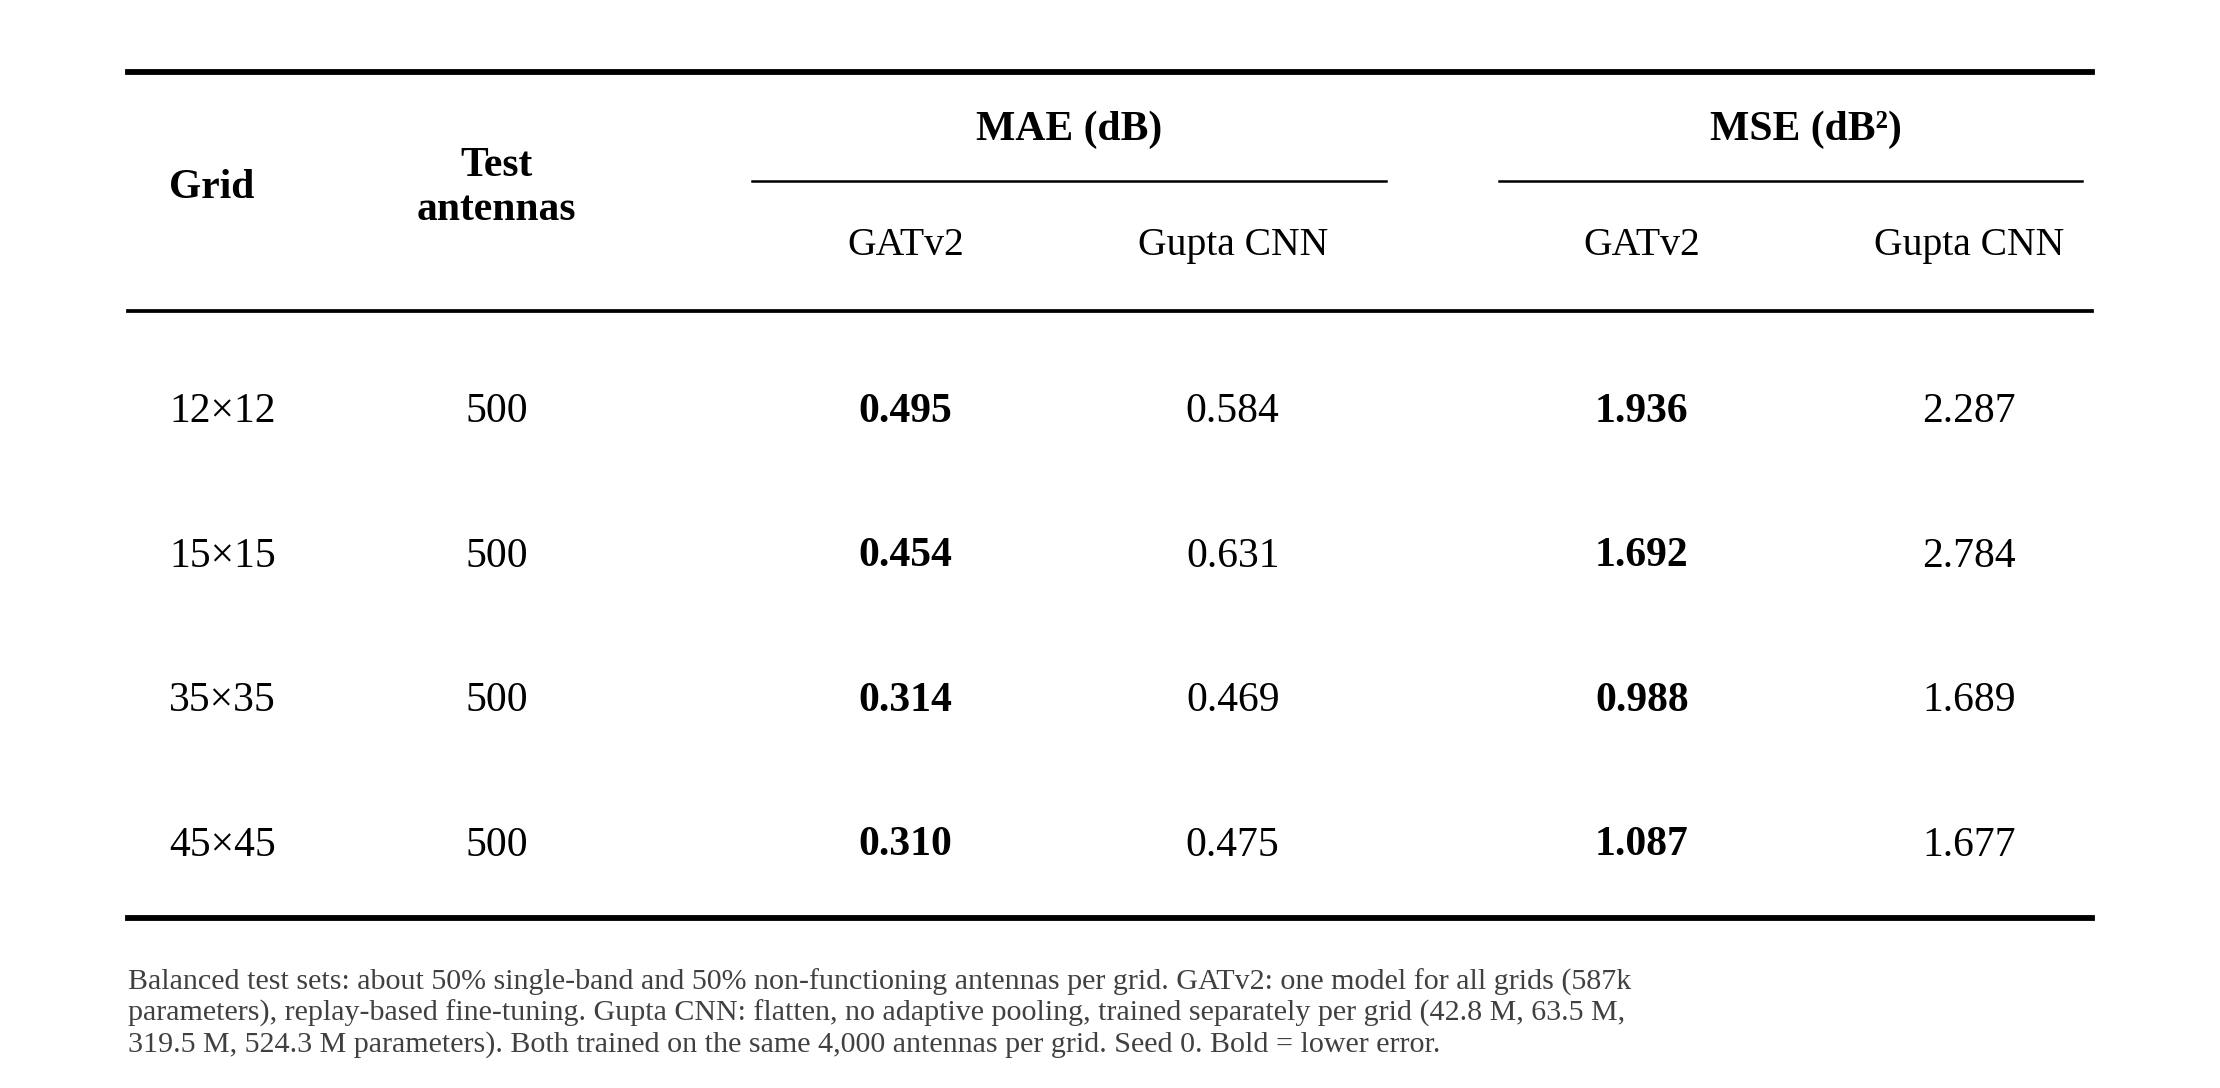

# Chunk 53 — Gupta CNN on the balanced single-band datasets; paired against the Chunk 52 GATv2

One test touch. 500 test antennas per grid (≈50% single-band / 50% non-functioning). 95% bootstrap intervals.

| grid | model | MSE (dB²) | MAE (dB) | R² | AUROC | MSE single-band | MSE non-functioning |
|---|---|---|---|---|---|---|---|
| 12×12 | bal_ft45_s0 | 1.936 [1.731, 2.132] | 0.495 [0.472, 0.516] | 0.642 | 0.750 | 3.054 [2.692, 3.405] | 0.818 [0.730, 0.920] |
| 12×12 | bal_ft45_s1 | 1.894 [1.692, 2.084] | 0.489 [0.467, 0.510] | 0.650 | 0.746 | 3.010 [2.655, 3.360] | 0.778 [0.692, 0.873] |
| 12×12 | cnn12_bal_s0 | 2.287 [2.063, 2.488] | 0.584 [0.562, 0.605] | 0.577 | 0.730 | 3.617 [3.264, 4.009] | 0.956 [0.830, 1.094] |
| 12×12 | cnn12_bal_s1 | 2.424 [2.195, 2.644] | 0.576 [0.553, 0.601] | 0.552 | 0.708 | 3.781 [3.405, 4.170] | 1.067 [0.908, 1.243] |
| 15×15 | bal_ft45_s0 | 1.692 [1.522, 1.859] | 0.454 [0.433, 0.475] | 0.729 | 0.821 | 2.703 [2.432, 2.989] | 0.681 [0.592, 0.782] |
| 15

In [15]:
# ── Table image and report ──
!apt-get -qq install -y fonts-liberation > /dev/null 2>&1
from matplotlib import font_manager
for f in glob.glob('/usr/share/fonts/truetype/liberation/*.ttf'):
    font_manager.fontManager.addfont(f)
FONT = next((f for f in ('Times New Roman', 'Liberation Serif', 'DejaVu Serif') if any(f == x.name for x in font_manager.fontManager.ttflist)), 'serif')
plt.rcParams.update({'font.family': 'serif', 'font.serif': [FONT], 'mathtext.fontset': 'stix', 'pdf.fonttype': 42})
fig = plt.figure(figsize=(7.2, 3.1), dpi=300); ax = fig.add_axes([0, 0, 1, 1]); ax.axis('off')
X = [0.04, 0.20, 0.40, 0.56, 0.76, 0.92]; top = 0.93
ax.text(X[0], top - .06, 'Grid', ha='left', va='center', fontsize=10, fontweight='bold')
ax.text(X[1], top - .06, 'Test\nantennas', ha='center', va='center', fontsize=10, fontweight='bold')
ax.text((X[2] + X[3]) / 2, top - .02, 'MAE (dB)', ha='center', va='center', fontsize=10, fontweight='bold')
ax.text((X[4] + X[5]) / 2, top - .02, 'MSE (dB²)', ha='center', va='center', fontsize=10, fontweight='bold')
for x, l in zip(X[2:], ['GATv2', 'Gupta CNN', 'GATv2', 'Gupta CNN']):
    ax.text(x, top - .10, l, ha='center', va='center', fontsize=9.5)
ax.plot([.02, .98], [top + .02] * 2, lw=1.4, color='k')
ax.plot([X[2] - .075, X[3] + .075], [top - .055] * 2, lw=.6, color='k'); ax.plot([X[4] - .07, .975], [top - .055] * 2, lw=.6, color='k')
ax.plot([.02, .98], [top - .145] * 2, lw=.9, color='k')
y, dy = top - .215, .10; TAB = []
for N in GRIDS:
    gm, gs = get('bal_ft45_s0', N, 'mae_db').estimate, get('bal_ft45_s0', N, 'mse_db2').estimate
    cm, cs = get(rid(N, 0), N, 'mae_db').estimate, get(rid(N, 0), N, 'mse_db2').estimate
    TAB.append(dict(grid=f'{N}x{N}', n_test=500, gatv2_mae=gm, cnn_mae=cm, gatv2_mse=gs, cnn_mse=cs, cnn_params=expected_cnn_params(N)))
    ax.text(X[0], y, f'{N}×{N}', ha='left', va='center', fontsize=10); ax.text(X[1], y, '500', ha='center', va='center', fontsize=10)
    for xg, xc, a, b in ((X[2], X[3], gm, cm), (X[4], X[5], gs, cs)):
        ax.text(xg, y, f'{a:.3f}', ha='center', va='center', fontsize=10, fontweight='bold' if a < b else 'normal')
        ax.text(xc, y, f'{b:.3f}', ha='center', va='center', fontsize=10, fontweight='bold' if b < a else 'normal')
    y -= dy
ax.plot([.02, .98], [y + dy / 2] * 2, lw=1.4, color='k')
mb = sorted(set(RUNS_DF[RUNS_DF.seed == 0].micro_batch))
note = ('Balanced test sets: about 50% single-band and 50% non-functioning antennas per grid. GATv2: one model for all grids '
        '(587k parameters), replay-based fine-tuning. Gupta CNN: flatten, no adaptive pooling, trained separately per grid ('
        + ', '.join(f'{expected_cnn_params(N) / 1e6:.1f} M' for N in GRIDS) + ' parameters). Both trained on the same 4,000 antennas per grid. '
        'Seed 0. Bold = lower error.' + ('' if mb == [256] else f' Some CNNs trained with micro-batches {mb} (effective batch 256).'))
ax.text(.02, y + dy / 2 - .035, '\n'.join(textwrap.wrap(note, 128)), ha='left', va='top', fontsize=7.2, color='0.25')
for ext in ('png', 'pdf'):
    fig.savefig(OUT(f'ch53_table_gatv2_vs_gupta_cnn.{ext}'), dpi=600 if ext == 'png' else None, bbox_inches='tight', pad_inches=.05, facecolor='white')
plt.show(); plt.close(fig)
pd.DataFrame(TAB).to_csv(OUT('ch53_table_values.csv'), index=False)
def fmt(mid, N, k, subset='all'):
    r = get(mid, N, k, subset); return f'{r.estimate:.3f}' if np.isnan(r.lo) else f'{r.estimate:.3f} [{r.lo:.3f}, {r.hi:.3f}]'
L = ['# Chunk 53 — Gupta CNN on the balanced single-band datasets; paired against the Chunk 52 GATv2', '',
     'One test touch. 500 test antennas per grid (≈50% single-band / 50% non-functioning). 95% bootstrap intervals.', '',
     '| grid | model | MSE (dB²) | MAE (dB) | R² | AUROC | MSE single-band | MSE non-functioning |', '|---|---|---|---|---|---|---|---|']
for N in GRIDS:
    for mid in GNN_IDS + sorted(RUNS_DF[RUNS_DF.grid == N].run_id):
        L.append(f'| {N}×{N} | {mid} | {fmt(mid, N, "mse_db2")} | {fmt(mid, N, "mae_db")} | {fmt(mid, N, "r2")} | {fmt(mid, N, "auroc")} | '
                 f'{fmt(mid, N, "mse_db2", "single_band")} | {fmt(mid, N, "mse_db2", "non_functioning")} |')
L += ['', '## Paired comparisons (A − B, same test antennas)', PAIR.round(4).to_markdown(index=False), '',
      '## Pre-registered statements'] + [f'- **{k}:** {t}' for k, t in ANS.items()]
L += ['', '## Table values', pd.DataFrame(TAB).round(4).to_markdown(index=False), '',
      '_Results apply to single-band and non-functioning antennas only; not comparable with the natural-distribution table._',
      '', '## Runs', RUNS_DF.drop(columns=['checkpoint_sha256'], errors='ignore').round(4).to_markdown(index=False)]
open(OUT('ch53_report.md'), 'w').write('\n'.join(L) + '\n'); print('\n'.join(L))

## 12. Guards
**What it checks:**
- one test touch
- the seed-0 CNNs exist for every grid, with the expected parameter counts
- every Chunk 53 checkpoint matches its recorded SHA-256
- every CNN trained on the 4,000-antenna Chunk 51 train set
- no run was stopped by its epoch cap
- input files unchanged, and no earlier file modified
- every output named `ch53_*`

In [17]:
# ── Guards ──
fails = []
def guard(ok, msg):
    print(f"  [{'PASS' if ok else 'FAIL'}] {msg}")
    if not ok: fails.append(msg)
R2 = pd.read_csv(RUNS)
guard(TEST_TOUCHES == 1, 'TEST touched exactly once')
guard({rid(N, 0) for N in GRIDS} <= set(R2.run_id), 'seed-0 CNN trained for every grid')
guard(all(r.n_params == expected_cnn_params(r.grid) for r in R2.itertuples()), 'parameter counts match the flatten-readout formula')
guard(all(sha(p) == h for p, h in zip(R2.checkpoint, R2.checkpoint_sha256)), 'every ch53 checkpoint matches its recorded SHA-256')
guard((R2.n_train == 4000).all(), 'every CNN trained on the 4,000-antenna Chunk 51 train set')
guard(not R2.budget_limited.any(), 'no run stopped by its epoch cap' if not R2.budget_limited.any() else f'BUDGET-LIMITED: {list(R2[R2.budget_limited].run_id)}')
guard(all(sha(p) == h for p, h in READ_SHA.items() if not Path(p).name.startswith('ch53_') and os.path.exists(p)), f'existing input files unchanged')
guard(all(os.path.getmtime(p) == t for p, t in PRIOR.items() if os.path.exists(p)), f'no earlier file modified ({len(PRIOR)})')
guard(all(Path(p).name.startswith('ch53_') for p in glob.glob(f'{ART}/ch53_*') + glob.glob(f'{CKPT}/ch53_*')), 'all outputs ch53_*')
if (R2.micro_batch < 256).any():
    print(f'  [NOTE] micro-batch below 256 (BatchNorm sees micro-batch statistics): {list(R2[R2.micro_batch < 256].run_id)}')
assert not fails, fails
print('ALL GUARDS PASSED')

  [PASS] TEST touched exactly once
  [PASS] seed-0 CNN trained for every grid
  [PASS] parameter counts match the flatten-readout formula
  [PASS] every ch53 checkpoint matches its recorded SHA-256
  [PASS] every CNN trained on the 4,000-antenna Chunk 51 train set
  [PASS] no run stopped by its epoch cap
  [PASS] existing input files unchanged
  [PASS] no earlier file modified (313)
  [PASS] all outputs ch53_*
ALL GUARDS PASSED
